In [2]:
%pip install numpy matplotlib nbconvert pandadoc scipy lalsuite gwpy > /dev/null
%load_ext autoreload
%autoreload 2

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")

import kalman
kalman.set_debug(0)

import kalman.chrono as chrono

import random
random.seed(42)

Note: you may need to restart the kernel to use updated packages.
The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Linear Kalman Filter: Ballistic Projectile Model 1D

KalmanStateModel(fs = 128Hz):

    Ballistic State Model (v1.0)
        State model for ballistic trajectories, simulating
        the motion of a projectile under the
        influence of gravity with constant
        acceleration.

    Dimensions Summary:
        State Vector....................................: 3 dims
        Control Input...................................: 1 dim
        Observation.....................................: 1 dim

    Initial State:
        State Vector (x0)...............................: 3x1 dims
        State Covariance (P0)...........................: 3x3 dims

    Matrix Information:
        System Dynamics F (also known as A).............: 3x3 dims
        Observation Matrix H (also known as C)..........: 1x3 dims

        Control Input B (also known as U)...............: 3x1 dims
        Process Noise Covariance Q (also known as W)....: 3x3 dims
        Measurement Noise Covariance R (also known as V): 1x1 dims

Chrono summary:
 1. Model initial

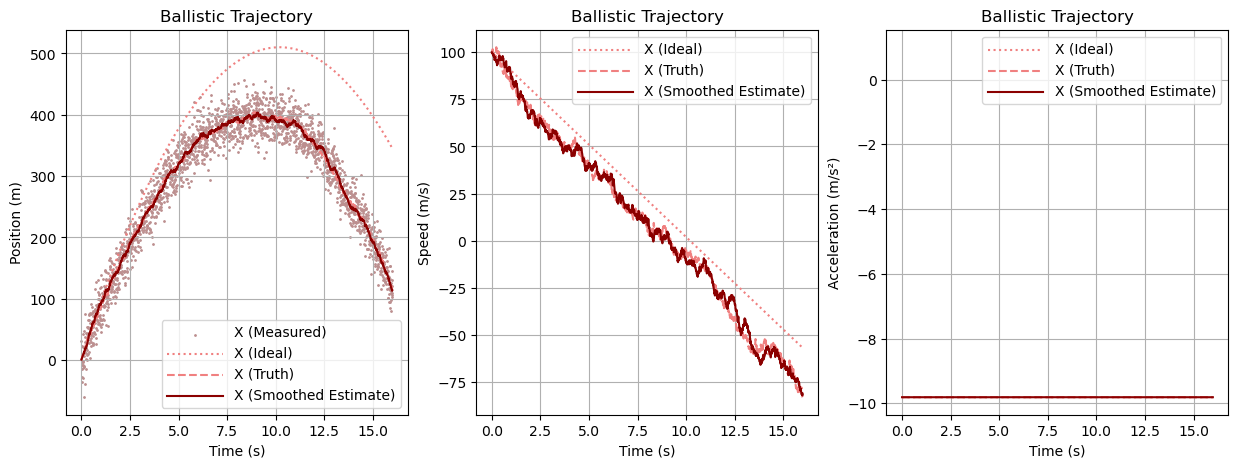

In [3]:
kalman.set_debug(0)

from kalman.models import BallisticStateModel
bulletbill = BallisticStateModel(dim=1, sample_rate=128, measurement_uncertainty=500, process_uncertainty=0.5, random_seed=42)
bulletbill.initial_state([0, 100, -9.81]) # Initial state: [x, vx, ax]
bulletbill.print()

chrono.restart()
chrono.lap("Model initialized")
zk, psik = bulletbill.sample(16)
chrono.lap("Sampling completed")
zk_hat, psik_hat = bulletbill.filter(zk, smooth=True, reset=True)
chrono.lap("Filtering completed")

from kalman.helpers import get_canvas
canvas = get_canvas(3, 1)

fig0 = bulletbill.plot(truth=psik, component="position",     fig=canvas[0])
chrono.lap("Position plot completed")
fig1 = bulletbill.plot(truth=psik, component="speed",        fig=canvas[1])
chrono.lap("Speed plot completed")
fig2 = bulletbill.plot(truth=psik, component="acceleration", fig=canvas[2])
chrono.lap("Acceleration plot completed")

chrono.summary()


## Linear Kalman Filter: Ballistic Projectile Model 3D

/Users/marcomeyer/Software/kalman/kalman-framework/share/notebooks/kalman/core/base.py:715: UserWarning: Initial state vector dimension expected 9x1, got 3x3. Automatic resizing applied.
  warnings.warn(


KalmanStateModel(fs = 128Hz):

    Ballistic State Model (v1.0)
        State model for ballistic trajectories, simulating
        the motion of a projectile under the
        influence of gravity with constant
        acceleration.

    Dimensions Summary:
        State Vector....................................: 9 dims
        Control Input...................................: 1 dim
        Observation.....................................: 3 dims

    Initial State:
        State Vector (x0)...............................: 9x1 dims
        State Covariance (P0)...........................: 9x9 dims

    Matrix Information:
        System Dynamics F (also known as A).............: 9x9 dims
        Observation Matrix H (also known as C)..........: 3x9 dims

        Control Input B (also known as U)...............: 9x1 dims
        Process Noise Covariance Q (also known as W)....: 9x9 dims
        Measurement Noise Covariance R (also known as V): 3x3 dims

Model initialized: 0.002478s
Sam

/Users/marcomeyer/.conda/envs/starformer/lib/python3.10/site-packages/IPython/core/events.py:82: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  func(*args, **kwargs)


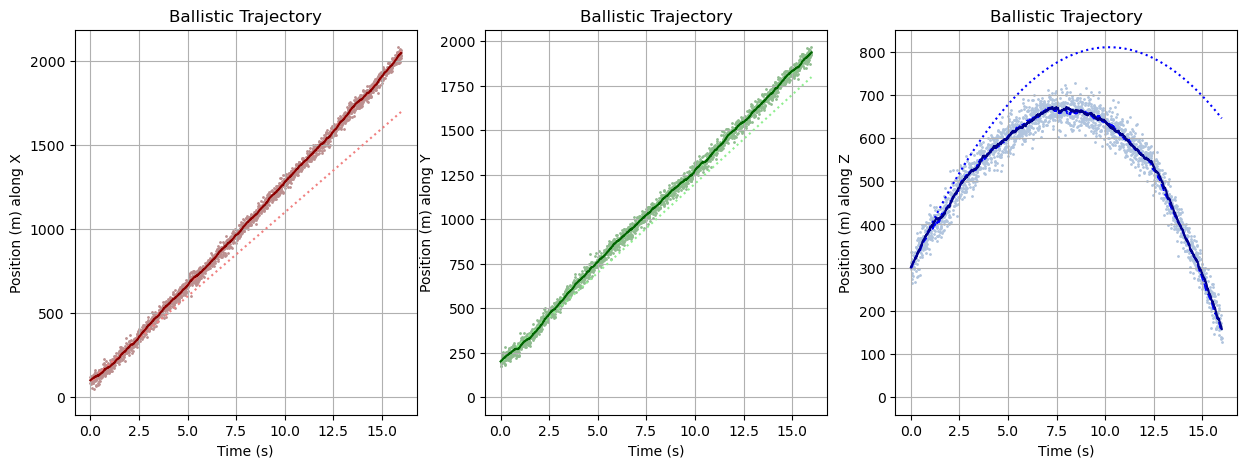

/Users/marcomeyer/.conda/envs/starformer/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


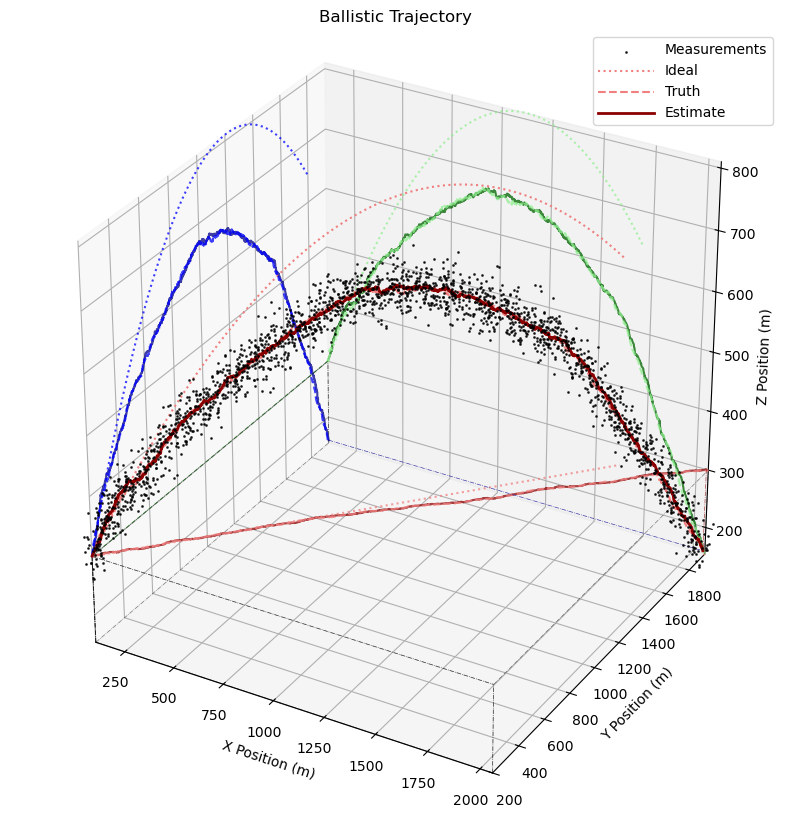

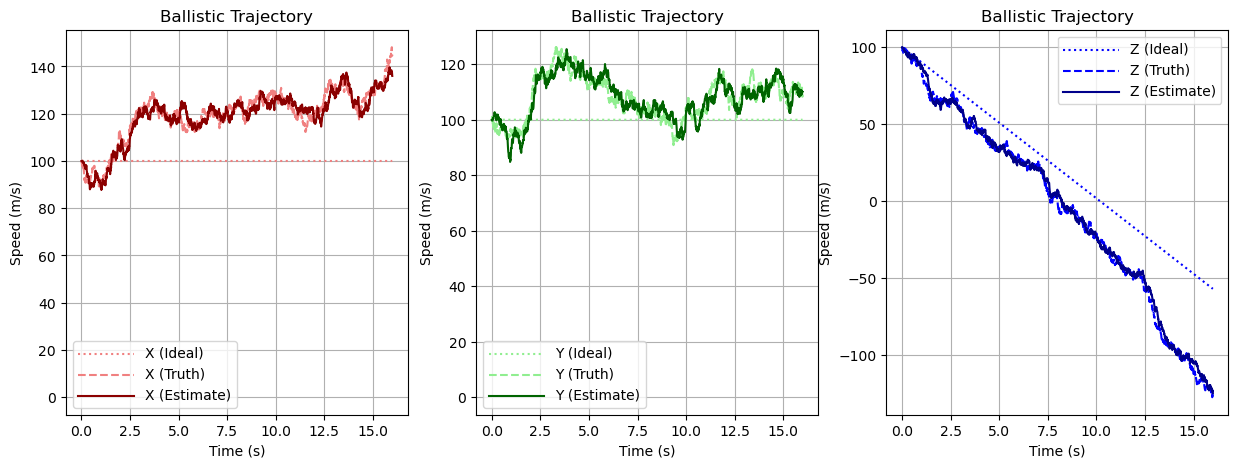

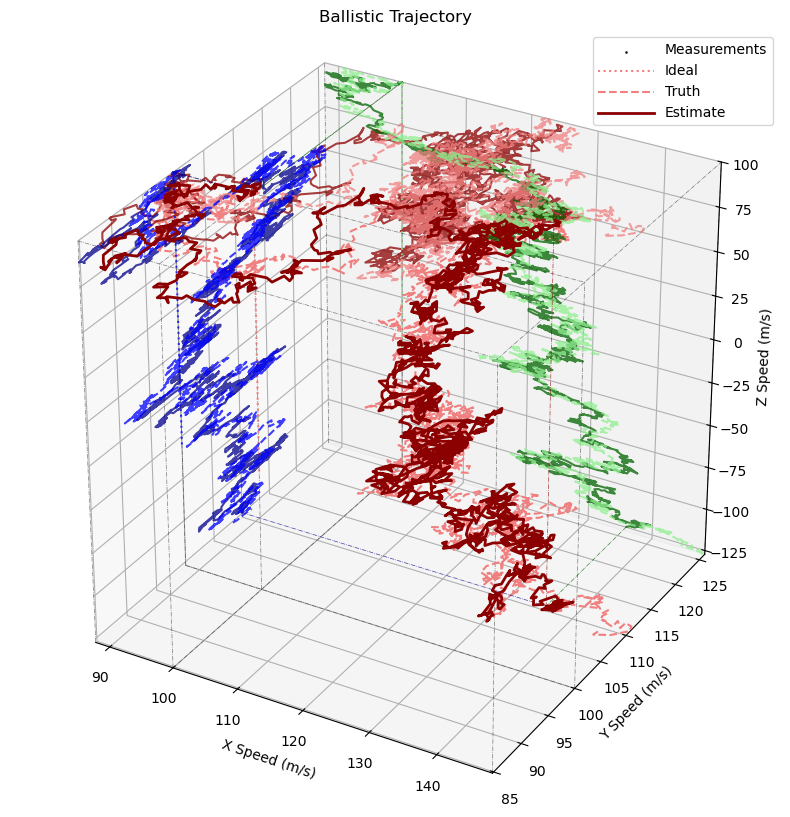

In [4]:
kalman.set_debug(0)

import kalman.chrono as chrono
chrono.restart()

from kalman.models import BallisticStateModel
bulletbill = BallisticStateModel(dim=3, sample_rate=128, measurement_uncertainty=500, process_uncertainty=0.5, random_seed=42)
bulletbill.initial_state([
    [100, 100, 0],    # Initial state: [x, vx, ax] 
    [200, 100, 0],    # Initial state: [y, vy, ay]
    [300, 100, -9.81] # Initial state: [x, vx, ax]
])
bulletbill.print()

print(chrono.lap("Model initialized"))
zk, psik = bulletbill.sample(16)
print(chrono.lap("Sampling completed"))

zk_hat, psik_hat = bulletbill.filter(zk, smooth=False, reset=True)
print(chrono.lap("Filtering completed"))

from kalman.helpers import get_canvas
canvas = get_canvas(3, 1)
bulletbill.plot(truth=psik, dim=0, component="position", legend = False, fig=canvas[0])
bulletbill.plot(truth=psik, dim=1, component="position", legend = False, fig=canvas[1])
bulletbill.plot(truth=psik, dim=2, component="position", legend = False, fig=canvas[2])
bulletbill.plot(truth=psik, component="position")
print(chrono.lap("Position plot completed"))

canvas = get_canvas(3, 1)
bulletbill.plot(truth=psik, dim=0, component="speed", fig=canvas[0])
bulletbill.plot(truth=psik, dim=1, component="speed", fig=canvas[1])
bulletbill.plot(truth=psik, dim=2, component="speed", fig=canvas[2])
bulletbill.plot(truth=psik, component="speed")
print(chrono.lap("Speed plot completed"))

# # Constant acceleration in Linear System (not very useful at the moment)
# canvas = get_canvas(3, 1)
# bulletbill.plot(truth=psik, dim=0, component="acceleration", fig=canvas[0])
# bulletbill.plot(truth=psik, dim=1, component="acceleration", fig=canvas[1])
# bulletbill.plot(truth=psik, dim=2, component="acceleration", fig=canvas[2])
# bulletbill.plot(truth=psik, component="acceleration")
# print(chrono.lap("Acceleration plot completed"))

## Power Grid 50/60Hz Model

## Violin Suspension Model